# Loss Tails Above a Threshold

This native Julia companion preserves the public NASDAQ observations, 2014 design cutoff, thresholds, tail models, bootstrap design and exception rules. The native fitting helper uses the original public simplex initialization and stopping tolerances; risk formulas and exception tests use RiskLabAI.jl. Fixed bootstrap positions reproduce seed 2202 without supplying fitted statistics. All calculations run in Julia. The resampling histogram retains the original bin convention and adds a panel whose bin bounds use the two drawdown measures. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## Defining public losses within a fixed sample

For a positive index level \(P_t\), the daily loss in percentage points is

$$
L_t=-100\log\!\left(\frac{P_t}{P_{t-1}}\right).
$$

Here, \(P_t\) is the public NASDAQ Composite level on date \(t\), \(P_{t-1}\) is the preceding valid level, and \(L_t\) is positive when the index falls. The design sample ends on 2014-12-31. The held-out sample begins with the next available return, so no held-out loss enters the threshold or the frozen tail fit.

4,Valid index observations,8055
5,Daily returns,8054
6,Download during execution,None
7,Simulated market observations,None


Row,Sample,First return,Last return,Returns
,String,Date,Date,Int64
1,Design,1994-01-04,2014-12-31,5287
2,Held out,2015-01-02,2025-12-31,2767
3,Complete,1994-01-04,2025-12-31,8054


Row,Sample,Observations,Mean loss (%),Standard deviation (%),95th percentile (%),99th percentile (%),Largest loss (%)
,String,Int64,Float64,Float64,Float64,Float64,Float64
1,Design,5287,-0.0343405,1.59963,2.61434,4.4378,10.1684
2,Held out,2767,-0.0574903,1.36433,2.21978,3.88409,13.1492
3,Complete,8054,-0.0422938,1.52285,2.5054,4.24981,13.1492


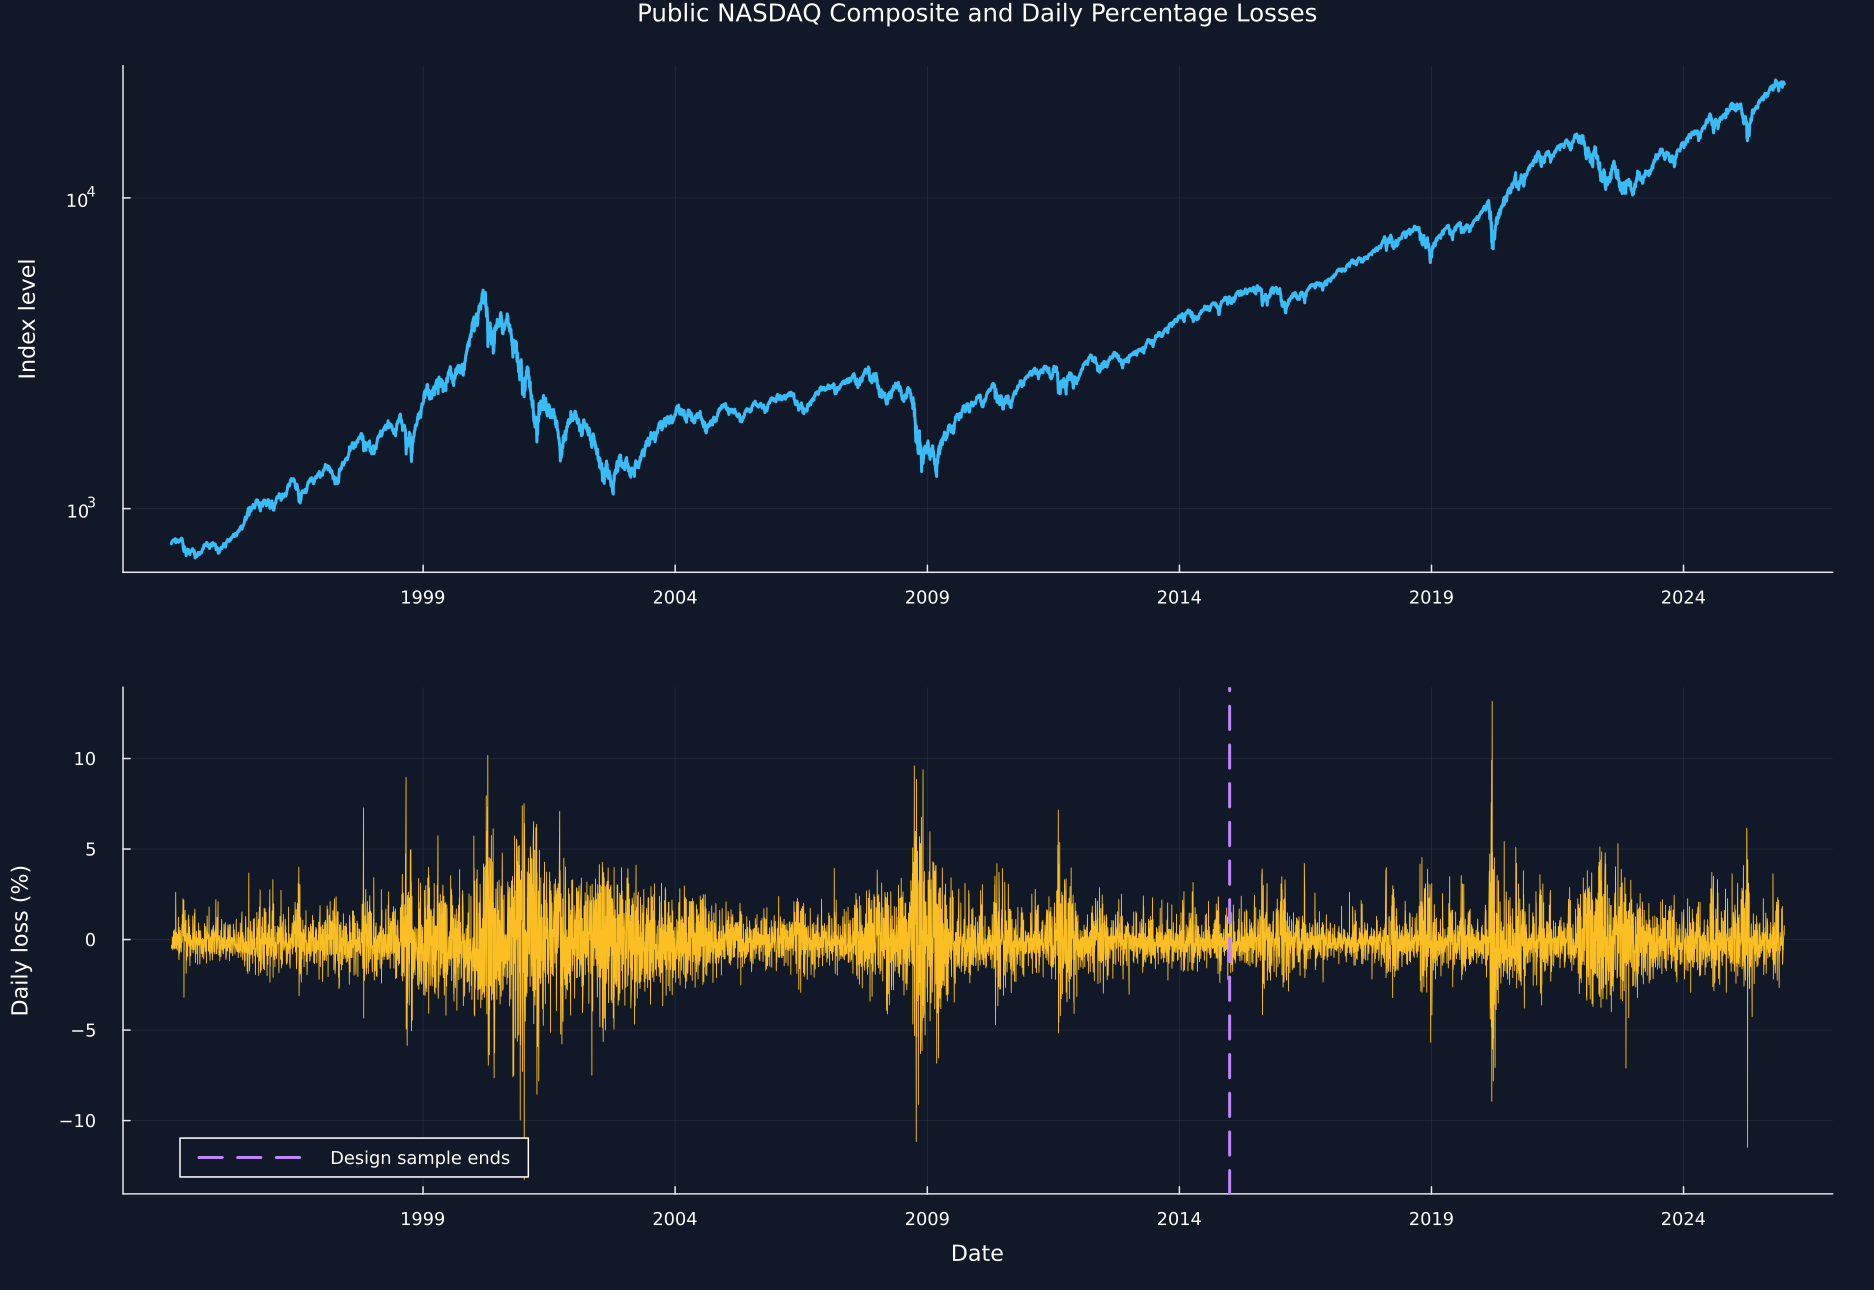

Row,Symbol,Description
,String,String
1,P(t),Index level on date t
2,L(t),Daily percentage loss
3,u,Loss threshold fixed from the design sample
4,Y,Positive excess L minus u when L exceeds u
5,xi,Generalized Pareto shape parameter
6,beta,Generalized Pareto scale parameter
7,p(u),Probability that a loss exceeds u


In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("21_tail_risk");
using CSV, TOML, Printf
using Distributions: Normal,quantile,pdf
using RiskLabAI.Backtest: expected_shortfall,conditional_expected_drawdown,generalized_pareto_tail_risk,quantile_exception_tests
include(joinpath("..","support","BookTailFit.jl"))
using .BookTailFit
source_path = dataset_path("fred_nasdaq")
@assert isfile(source_path)
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:NASDAQCOM)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.NASDAQCOM)
log_returns = 100 .*log.(prices[2:end]./prices[1:end-1])
losses = -log_returns
simple_returns = expm1.(log_returns./100)
dates = price_dates[2:end]
design = findall(dates.<=Date(2014,12,31))
held = findall(dates.>=Date(2015,1,1))
design_losses,held_losses = losses[design],losses[held]
@assert length(design)==5287
@assert length(held)==2767
@assert last(dates[design])<first(dates[held])
@assert length(design)+length(held)==length(losses)
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
date_ticks(values;step=5) = let ticks=filter(date->first(values)<=date<=last(values),Date.(collect(year(first(values)):step:year(last(values))),1,1)); (Dates.value.(ticks),string.(year.(ticks))) end
save_data(DataFrame(date=dates,price=prices[2:end],log_return=log_returns,loss=losses,simple_return=simple_returns),paths,"threshold_observations")

function empirical_tail(values,probability)
    ordered = sort(values)
    count = (1-probability)*length(values)
    complete = floor(Int,count)
    total = complete>0 ? sum(ordered[end-complete+1:end]) : 0.
    fraction = count-complete
    fraction>0 && (total += fraction*ordered[end-complete])
    return total/count
end

function path_drawdown(values)
    wealth = cumprod(1 .+ values)
    return 1 .- wealth./accumulate(max,wealth)
end

function rolling_drawdowns(values,horizon)
    wealth = cumprod(1 .+ values)
    length(wealth)<horizon && return [maximum(path_drawdown(values))]
    return [maximum(1 .- current./accumulate(max,current)) for current in (view(wealth,start:start+horizon-1) for start in 1:length(wealth)-horizon+1)]
end

function annual_forecast(probability)
    forecast = zeros(length(held))
    records = NamedTuple[]
    for forecast_year in sort(unique(year.(dates[held])))
        history = findall(dates.<Date(forecast_year,1,1))
        threshold = quantile(losses[history],.95)
        fit = fit_public_pot(losses[history];threshold,probability)
        forecast[year.(dates[held]).==forecast_year] .= fit.value_at_risk
        push!(records,(year=forecast_year,through=last(dates[history]),observations=length(history),threshold=threshold,excesses=fit.exceedance_count,shape=fit.shape,scale=fit.scale,var=fit.value_at_risk,es=fit.expected_shortfall))
    end
    frame = DataFrame(records)
    rename!(frame,["Forecast year","History through","History observations","Threshold (%)","Excesses","Shape","Scale (%)","Forecast VaR (%)","Forecast ES (%)"])
    @assert all(year.(frame[!,"History through"]).<frame[!,"Forecast year"])
    @assert all(isfinite,forecast)
    return forecast,frame
end

function forecasts_at(probability)
    threshold = quantile(design_losses,.95)
    fit = fit_public_pot(design_losses;threshold,probability)
    annual,records = annual_forecast(probability)
    forecasts = [fill(mean(design_losses)+std(design_losses)*quantile(Normal(),probability),length(held)),fill(quantile(design_losses,probability),length(held)),fill(fit.value_at_risk,length(held)),annual]
    return forecasts,records
end

forecast_names = ["Gaussian","Empirical","Generalized Pareto","Annual generalized Pareto"]
forecast_colors = [palette.amber,palette.green,palette.cyan,violet]
provenance = DataFrame("Item"=>["Public series","Stored file","Valid index observations","Daily returns","Download during execution","Simulated market observations"],"Value"=>["NASDAQ Composite, FRED NASDAQCOM",basename(source_path),string(length(prices)),string(length(losses)),"None","None"])
table(provenance,"data_provenance","Public data provenance for Chapter 21.")
sample_indices = [design,held,collect(eachindex(losses))]
sample_names = ["Design","Held out","Complete"]
periods = DataFrame("Sample"=>sample_names,"First return"=>[first(dates[rows]) for rows in sample_indices],"Last return"=>[last(dates[rows]) for rows in sample_indices],"Returns"=>length.(sample_indices))
table(periods,"sample_periods","Chronological sample boundaries.")
loss_summary = DataFrame([(sample=name,observations=length(rows),average=mean(losses[rows]),deviation=std(losses[rows]),q95=quantile(losses[rows],.95),q99=quantile(losses[rows],.99),maximum=maximum(losses[rows])) for (name,rows) in zip(sample_names,sample_indices)])
rename!(loss_summary,["Sample","Observations","Mean loss (%)","Standard deviation (%)","95th percentile (%)","99th percentile (%)","Largest loss (%)"])
table(loss_summary,"loss_summary_by_period","Loss summaries for the fixed samples.")
history = DataFrame("Date"=>price_dates,"NASDAQ Composite"=>prices,"Loss (%)"=>vcat(NaN,losses))
save_data(history,paths,"public_price_loss_history")
p1 = plot(Dates.value.(price_dates),prices;yscale=:log10,xticks=date_ticks(price_dates),color=palette.cyan,label="",ylabel="Index level",title="Public NASDAQ Composite and Daily Percentage Losses")
p2 = plot(Dates.value.(dates),losses;xticks=date_ticks(price_dates),color=palette.amber,label="",linewidth=.6,ylabel="Daily loss (%)",xlabel="Date",legend=:bottomleft)
vline!(p2,[Dates.value(Date(2014,12,31))];color=violet,linestyle=:dash,label="Design sample ends")
save_figure(plot(p1,p2;layout=(2,1),size=(1250,860)),paths,"public_price_loss_history")
@assert length(prices)==8055 && length(losses)==8054
notation = DataFrame("Symbol"=>["P(t)", "L(t)", "u", "Y", "xi", "beta", "p(u)"],"Description"=>["Index level on date t", "Daily percentage loss", "Loss threshold fixed from the design sample", "Positive excess L minus u when L exceeds u", "Generalized Pareto shape parameter", "Generalized Pareto scale parameter", "Probability that a loss exceeds u"])
table(notation,"tail_notation","Tail notation.")


## Modeling threshold excesses with the generalized Pareto law

For a threshold \(u\), define the excess \(Y=L-u\) only when \(L>u\). The generalized Pareto survival law is

$$
\Pr(Y>y\mid L>u)=\left(1+\frac{\xi y}{\beta}\right)^{-1/\xi},
$$

on values of \(y\geq 0\) for which \(1+\xi y/\beta>0\). The scale parameter \(\beta>0\) sets the size of excesses. The shape parameter \(\xi\) controls how slowly the tail declines. When \(\xi=0\), the continuous limit is the exponential survival law \(\exp(-y/\beta)\).

Row,Design percentile,Threshold (%),Excesses,Exceedance proportion,Mean excess (%),Largest excess (%)
,Float64,Float64,Int64,Float64,Float64,Float64
1,0.9,1.83114,529,0.100057,1.17078,8.33727
2,0.925,2.17487,397,0.0750898,1.15877,7.99354
3,0.95,2.61434,265,0.0501229,1.19609,7.55407
4,0.975,3.30398,133,0.025156,1.38023,6.86443


Row,Quantity,Value
,String,Float64
1,Threshold percentile,0.95
2,Threshold (%),2.61434
3,Design observations,5287.0
4,Positive excesses,265.0
5,Exceedance probability,0.0501229
6,Shape,0.135989
7,Scale (%),1.03608


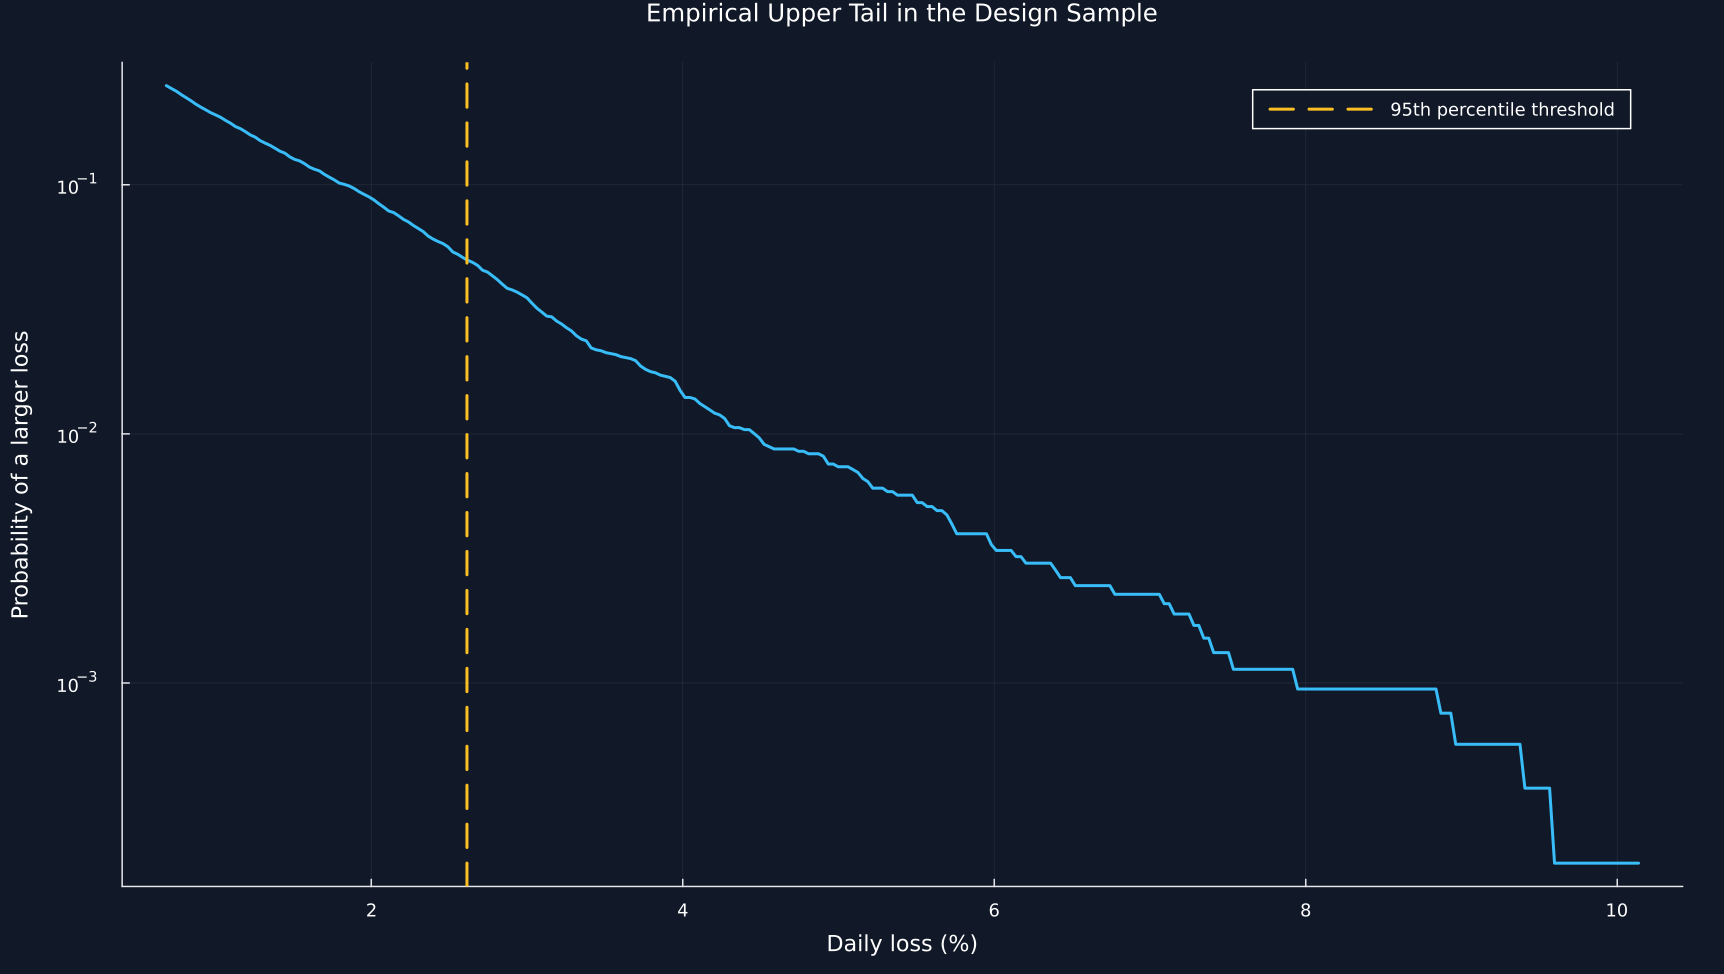

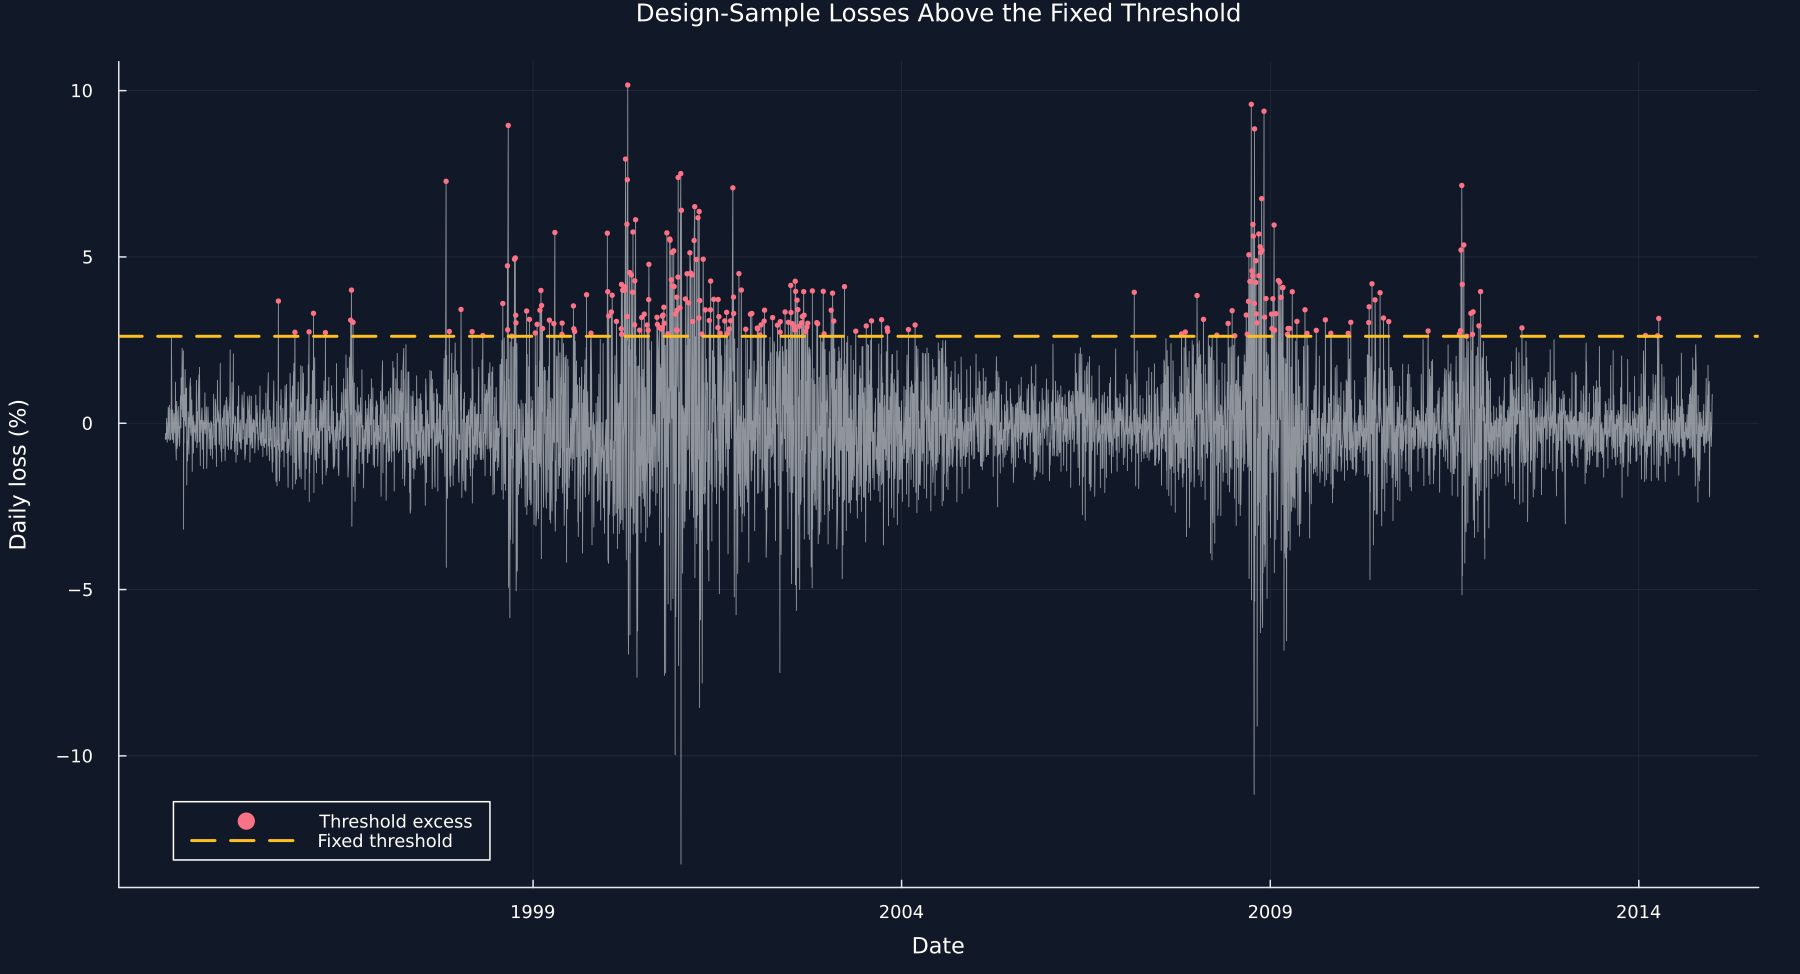

In [2]:
threshold_levels = [.90,.925,.95,.975]
threshold_counts = DataFrame([(level=level,threshold=threshold,excesses=length(excesses),rate=length(excesses)/length(design_losses),average=mean(excesses),largest=maximum(excesses)) for level in threshold_levels for threshold in [quantile(design_losses,level)] for excesses in [design_losses[design_losses.>threshold].-threshold]])
rename!(threshold_counts,["Design percentile","Threshold (%)","Excesses","Exceedance proportion","Mean excess (%)","Largest excess (%)"])
table(threshold_counts,"threshold_counts","Design-sample thresholds and excess counts.")
primary_threshold = quantile(design_losses,.95)
primary_fit = fit_public_pot(design_losses;threshold=primary_threshold,probability=.99)
primary_parameters = DataFrame("Quantity"=>["Threshold percentile","Threshold (%)","Design observations","Positive excesses","Exceedance probability","Shape","Scale (%)"],"Value"=>[.95,primary_threshold,primary_fit.sample_count,primary_fit.exceedance_count,primary_fit.exceedance_probability,primary_fit.shape,primary_fit.scale])
table(primary_parameters,"pot_primary_parameters","Primary generalized Pareto fit from the design sample.")
survival_grid = collect(range(max(0.,quantile(design_losses,.75)),maximum(design_losses);length=300))
survival = DataFrame("Loss (%)"=>survival_grid,"Empirical survival probability"=>[mean(design_losses.>value) for value in survival_grid])
save_data(survival,paths,"empirical_loss_survival")
positive = survival[!,"Empirical survival probability"].>0
figure = plot(survival_grid[positive],survival[positive,"Empirical survival probability"];yscale=:log10,color=palette.cyan,label="",xlabel="Daily loss (%)",ylabel="Probability of a larger loss",title="Empirical Upper Tail in the Design Sample",legend=:topright,size=(1150,650))
vline!(figure,[primary_threshold];color=palette.amber,linestyle=:dash,label="95th percentile threshold")
save_figure(figure,paths,"empirical_loss_survival")
timeline = DataFrame("Date"=>dates[design],"Loss (%)"=>design_losses,"Exceeds threshold"=>design_losses.>primary_threshold,"Threshold (%)"=>fill(primary_threshold,length(design)))
save_data(timeline,paths,"threshold_exceedance_timeline")
figure = plot(Dates.value.(dates[design]),design_losses;xticks=date_ticks(dates[design]),color=palette.text,alpha=.6,linewidth=.6,label="",xlabel="Date",ylabel="Daily loss (%)",title="Design-Sample Losses Above the Fixed Threshold",legend=:bottomleft,size=(1200,650))
marked = timeline[!,"Exceeds threshold"]
scatter!(figure,Dates.value.(dates[design][marked]),design_losses[marked];color=palette.rose,markersize=2,label="Threshold excess",markerstrokewidth=0)
hline!(figure,[primary_threshold];color=palette.amber,linestyle=:dash,label="Fixed threshold")
save_figure(figure,paths,"threshold_exceedance_timeline")
@assert primary_fit.exceedance_count==265
@assert primary_fit.scale>0
@assert all(1 .+ primary_fit.shape.*(design_losses[marked].-primary_threshold)./primary_fit.scale .>0)


## Testing generalized Pareto fit across thresholds

For positive excesses \(y_1,\ldots,y_k\), the log likelihood is

$$
\ell(\xi,\beta)=-k\log\beta-\left(1+\frac{1}{\xi}\right)\sum_{i=1}^{k}\log\!\left(1+\frac{\xi y_i}{\beta}\right),
$$

when \(\xi\neq 0\) and every support term is positive. Here, \(k\) is the number of excesses, \(y_i\) is excess \(i\), \(\xi\) is the shape, and \(\beta\) is the positive scale. The fitting calculation fixes the excess location at zero and chooses the shape and scale numerically. A numerical maximum is a fitted solution, not a proof of a unique global maximum.

The mean excess function at a candidate threshold \(u\) is

$$
e(u)=\mathbb{E}[L-u\mid L>u].
$$

The value \(e(u)\) is the average distance above \(u\), using only losses that exceed \(u\). A nearly linear pattern over a range of high thresholds is one useful diagnostic, but it does not determine a unique threshold.

Row,Threshold percentile,Threshold (%),Excesses,Shape,Scale (%),99% VaR (%),99% ES (%),Smallest support term,Log likelihood
,Float64,Float64,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.9,1.83114,529,0.066155,1.09319,4.55085,5.91415,1.00003,-611.179
2,0.925,2.17487,397,0.112127,1.0298,4.50445,5.95849,1.00014,-453.165
3,0.95,2.61434,265,0.135989,1.03608,4.48156,5.9746,1.00006,-310.426
4,0.975,3.30398,133,0.0322085,1.33595,4.5549,5.97693,1.00002,-175.806


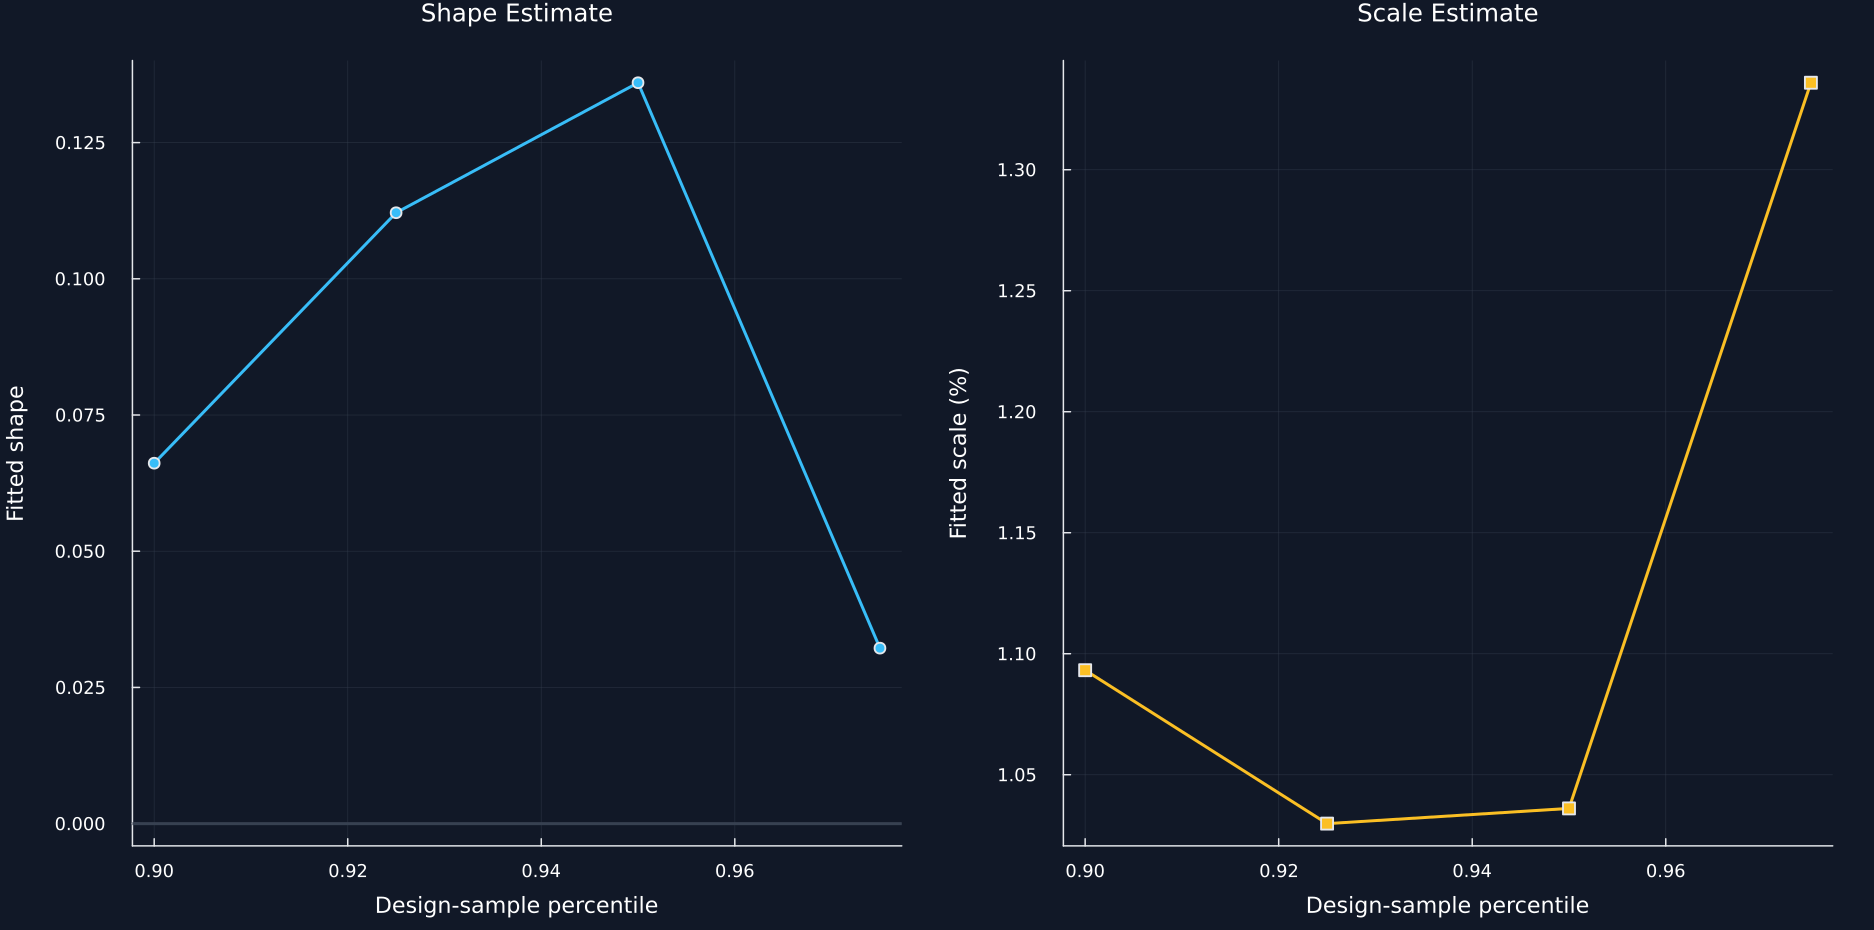

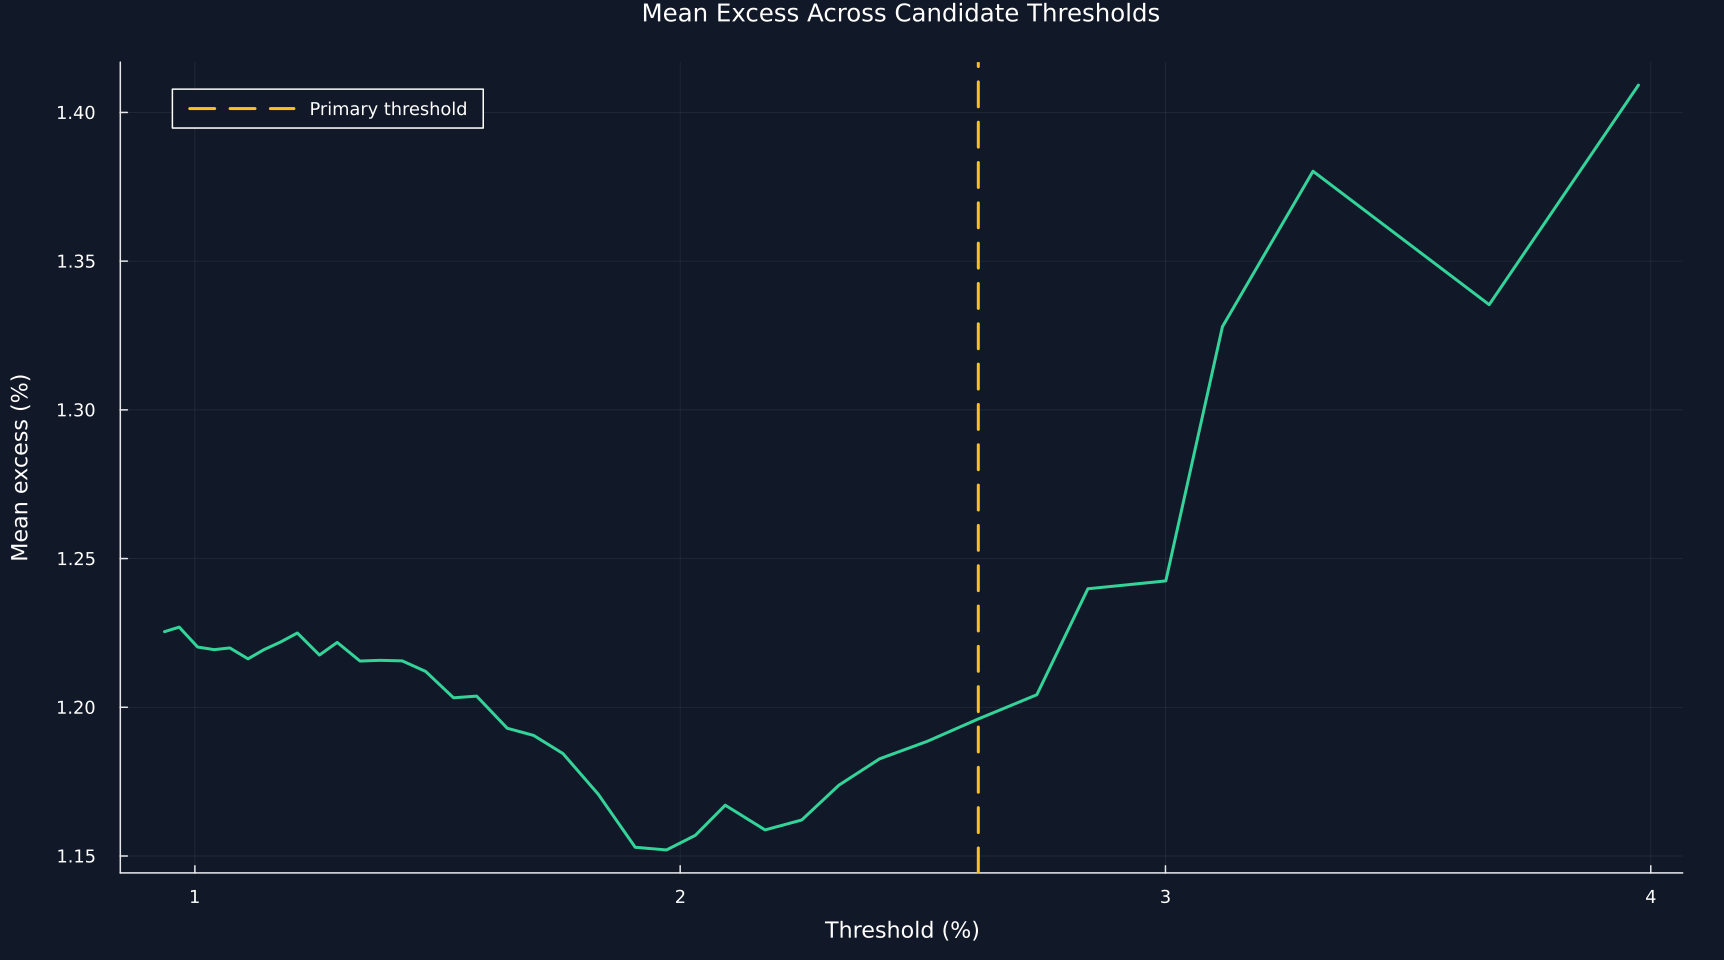

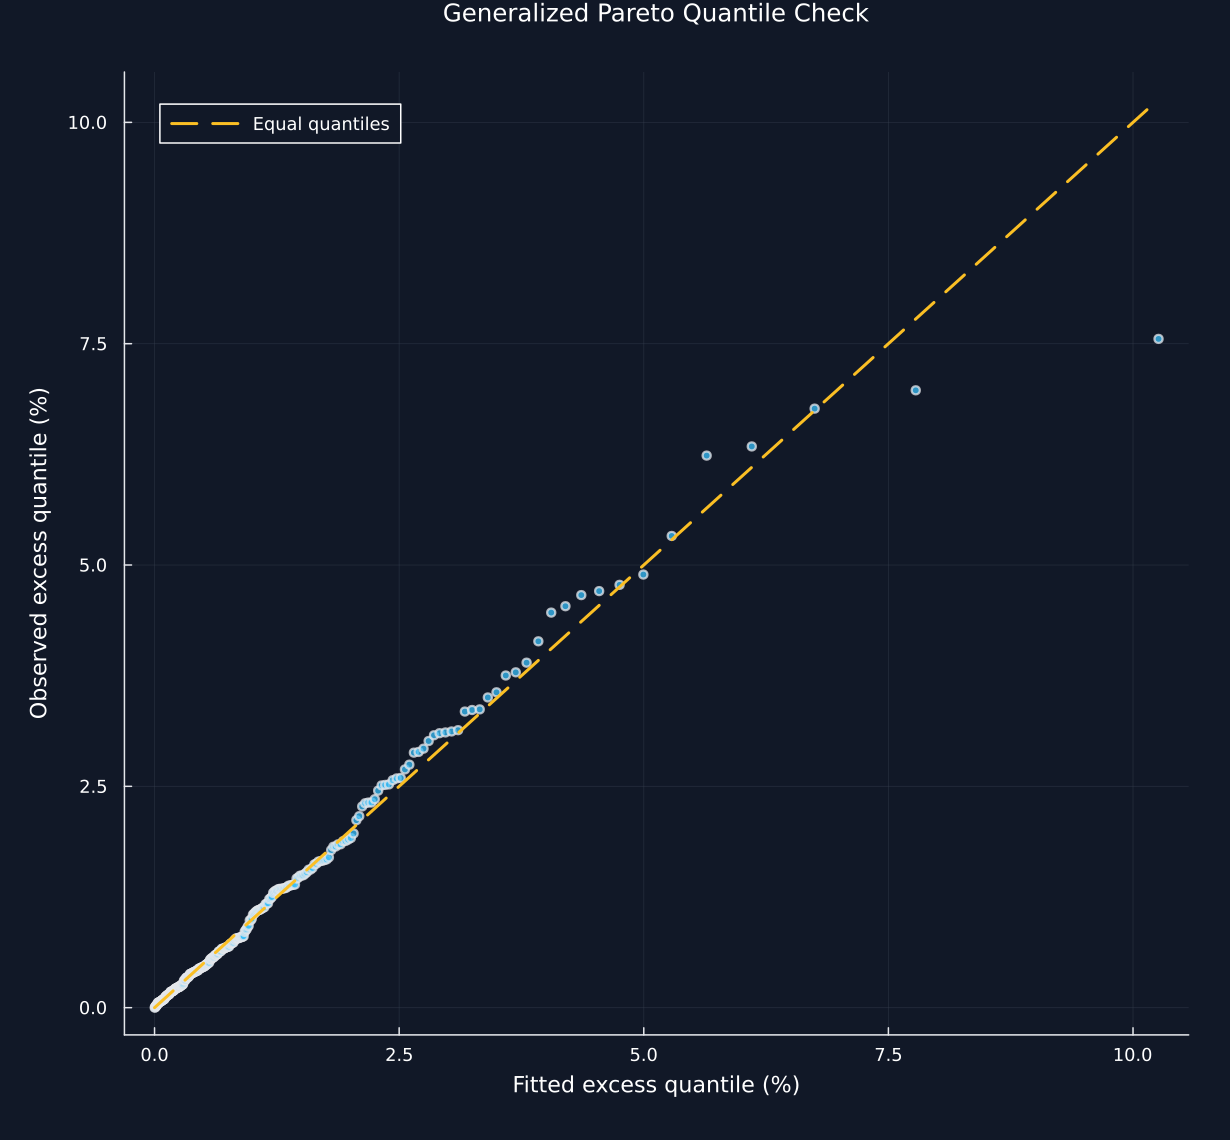

Row,Check,Value,Required condition
,String,Bool,String
1,Threshold uses design sample only,true,Pass
2,Positive distinct excesses,true,Pass
3,Positive fitted scale,true,Pass
4,Support terms positive,true,Pass
5,Finite fitted log likelihood,true,Pass


Row,Question,Answer
,String,String
1,What is fitted?,Positive excesses above a supplied threshold
2,What is not fitted?,The full loss distribution
3,How is the threshold chosen?,From the design sample before held-out evaluation
4,What does a diagnostic establish?,"Finite-sample fit behavior, not truth"
5,What can dependence change?,Uncertainty and finite-sample stability


In [3]:
sensitivity_rows = NamedTuple[]
fit_records = NamedTuple[]
for level in [.90,.925,.95,.975]
    threshold = quantile(design_losses,level)
    fit = fit_public_pot(design_losses;threshold,probability=.99)
    excesses = design_losses[design_losses.>threshold].-threshold
    support = minimum(1 .+ fit.shape.*excesses./fit.scale)
    likelihood = -pareto_objective([fit.shape,fit.scale],excesses)
    push!(sensitivity_rows,(level=level,threshold=threshold,excesses=fit.exceedance_count,shape=fit.shape,scale=fit.scale,var=fit.value_at_risk,es=fit.expected_shortfall,support=support,likelihood=likelihood))
    push!(fit_records,(level=level,iterations=fit.iterations,evaluations=fit.evaluations,objective=fit.negative_log_likelihood))
end
sensitivity = DataFrame(sensitivity_rows)
rename!(sensitivity,["Threshold percentile","Threshold (%)","Excesses","Shape","Scale (%)","99% VaR (%)","99% ES (%)","Smallest support term","Log likelihood"])
table(sensitivity,"pot_threshold_sensitivity","Generalized Pareto sensitivity to the design-sample threshold.")
save_data(DataFrame(fit_records),paths,"threshold_fit_iterations")
parameter_data = select(sensitivity,["Threshold percentile","Shape","Scale (%)","99% VaR (%)","99% ES (%)"])
save_data(parameter_data,paths,"threshold_parameter_stability")
p1 = plot(parameter_data[!,"Threshold percentile"],parameter_data.Shape;color=palette.cyan,marker=:circle,label="",xlabel="Design-sample percentile",ylabel="Fitted shape",title="Shape Estimate")
hline!(p1,[0.];color=palette.grid,label="")
p2 = plot(parameter_data[!,"Threshold percentile"],parameter_data[!,"Scale (%)"];color=palette.amber,marker=:square,label="",xlabel="Design-sample percentile",ylabel="Fitted scale (%)",title="Scale Estimate")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,620)),paths,"threshold_parameter_stability")
mean_excess_rows = NamedTuple[]
for index in 0:37
    level = .80+index*((.80+.005)-.80)
    threshold = quantile(design_losses,level)
    excesses = design_losses[design_losses.>threshold].-threshold
    push!(mean_excess_rows,(level=level,threshold=threshold,average=mean(excesses),excesses=length(excesses)))
end
mean_excess = DataFrame(mean_excess_rows)
rename!(mean_excess,["Threshold percentile","Threshold (%)","Mean excess (%)","Excesses"])
save_data(mean_excess,paths,"mean_excess_diagnostic")
figure = plot(mean_excess[!,"Threshold (%)"],mean_excess[!,"Mean excess (%)"];color=palette.green,label="",xlabel="Threshold (%)",ylabel="Mean excess (%)",title="Mean Excess Across Candidate Thresholds",legend=:topleft,size=(1150,640))
vline!(figure,[primary_threshold];color=palette.amber,linestyle=:dash,label="Primary threshold")
save_figure(figure,paths,"mean_excess_diagnostic")
excesses = sort(design_losses[design_losses.>primary_threshold].-primary_threshold)
probabilities = ((1:length(excesses)).-.5)./length(excesses)
theoretical = primary_fit.scale.*expm1.(-primary_fit.shape.*log1p.(-probabilities))./primary_fit.shape
qq = DataFrame("Fitted quantile (%)"=>theoretical,"Observed excess (%)"=>excesses)
save_data(qq,paths,"generalized_pareto_qq")
figure = scatter(theoretical,excesses;color=palette.cyan,markersize=3,alpha=.75,label="",xlabel="Fitted excess quantile (%)",ylabel="Observed excess quantile (%)",title="Generalized Pareto Quantile Check",legend=:topleft,size=(820,760))
limit = max(maximum(theoretical),maximum(excesses))
plot!(figure,[0.,limit],[0.,limit];color=palette.amber,linestyle=:dash,label="Equal quantiles")
save_figure(figure,paths,"generalized_pareto_qq")
checks = DataFrame("Check"=>["Threshold uses design sample only","Positive distinct excesses","Positive fitted scale","Support terms positive","Finite fitted log likelihood"],"Value"=>[last(dates[design])<first(dates[held]),length(excesses)>=2&&maximum(excesses)>minimum(excesses),primary_fit.scale>0,minimum(sensitivity[!,"Smallest support term"])>0,all(isfinite,sensitivity[!,"Log likelihood"])],"Required condition"=>fill("Pass",5))
table(checks,"support_likelihood_checks","Support and likelihood checks for the primary fit.")
@assert all(checks.Value)
limits = DataFrame("Question"=>["What is fitted?", "What is not fitted?", "How is the threshold chosen?", "What does a diagnostic establish?", "What can dependence change?"],"Answer"=>["Positive excesses above a supplied threshold", "The full loss distribution", "From the design sample before held-out evaluation", "Finite-sample fit behavior, not truth", "Uncertainty and finite-sample stability"])
table(limits,"tail_model_limits","Tail model limits.")


## Extrapolating high loss quantiles

If \(p_u=\Pr(L>u)\), the fitted probability of a loss above \(x>u\) is

$$
\widehat{\Pr}(L>x)=\widehat p_u\left(1+\frac{\widehat\xi(x-u)}{\widehat\beta}\right)^{-1/\widehat\xi}.
$$

Here, \(\widehat p_u=k/n\) is the design-sample fraction above the threshold, \(n\) is the number of design losses, and \(k\) is the excess count. The fitted shape and scale are \(\widehat\xi\) and \(\widehat\beta\). For a target probability \(p>1-\widehat p_u\), inversion gives

$$
\widehat q_p=u+\frac{\widehat\beta}{\widehat\xi}\left[\left(\frac{1-p}{\widehat p_u}\right)^{-\widehat\xi}-1\right],
$$

with the exponential limit used when \(\widehat\xi=0\). The quantity \(\widehat q_p\) is the fitted loss quantile whose exceedance probability is \(1-p\).

Row,Quantile probability,Tail probability,Value at risk (%),Expected shortfall (%)
,Float64,Float64,Float64,Float64
1,0.975,0.025,3.37022,4.68835
2,0.99,0.01,4.48156,5.9746
3,0.995,0.005,5.41922,7.05984


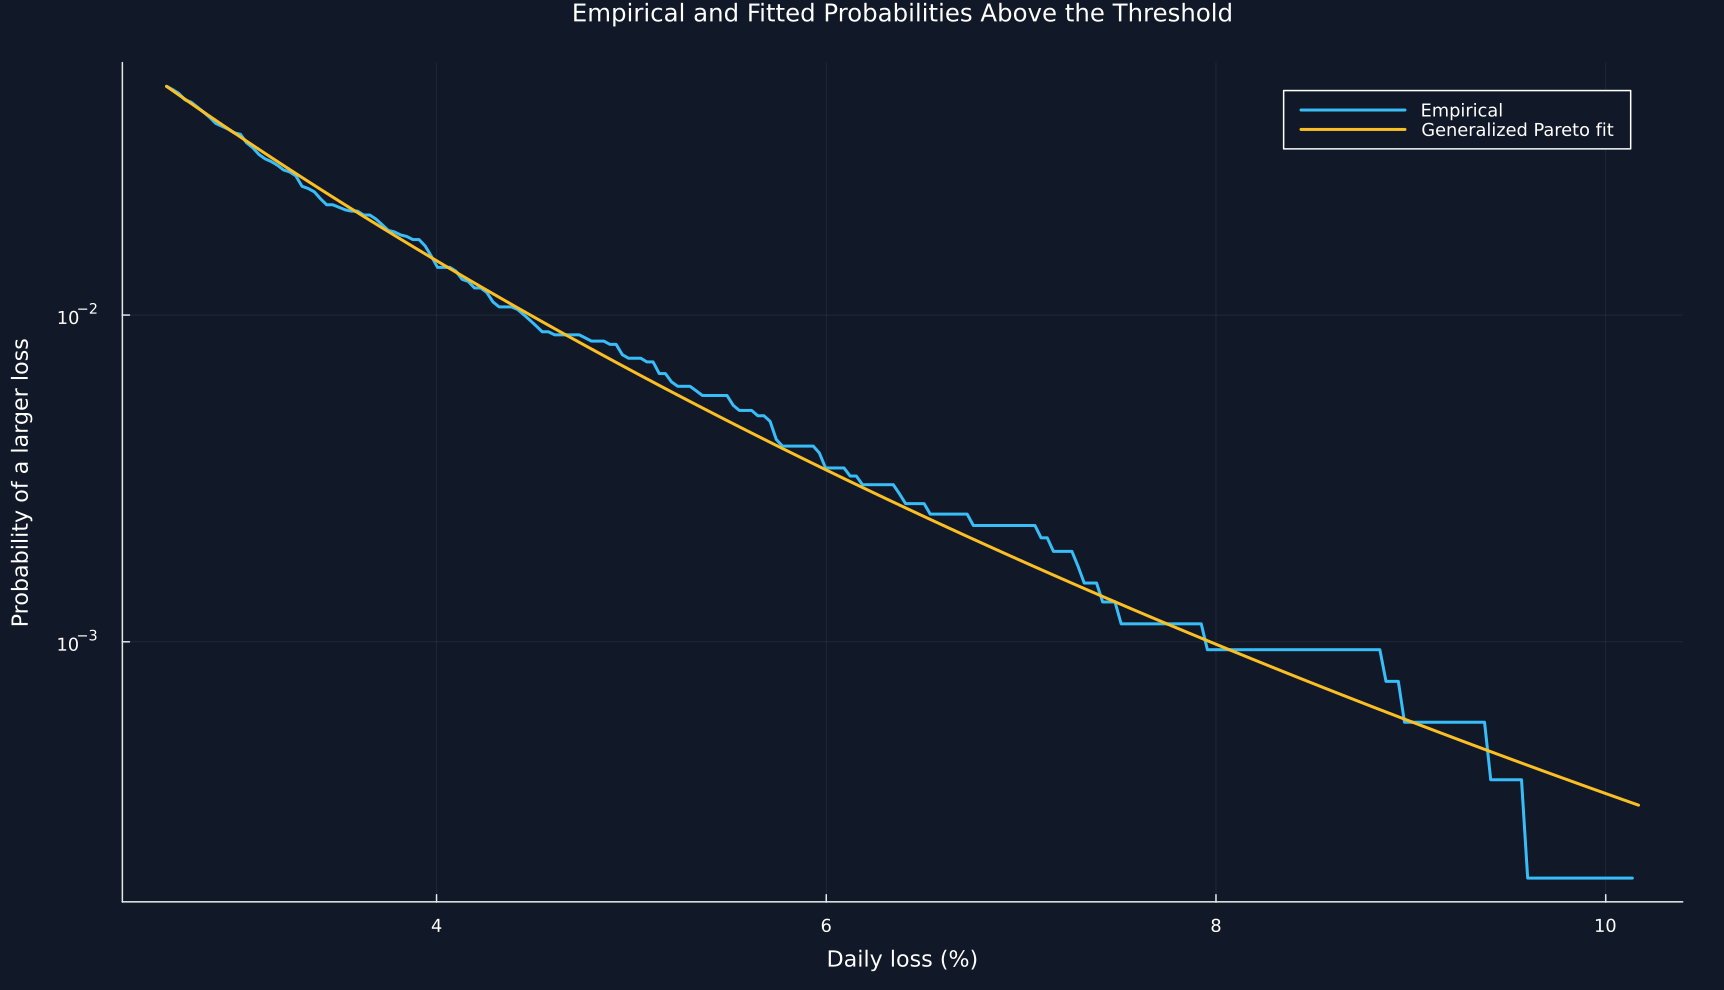

In [4]:
fit = primary_fit
risk_estimates = DataFrame([(probability=probability,tail=1-probability,var=risk.value_at_risk,es=risk.expected_shortfall) for probability in [.975,.99,.995] for risk in [generalized_pareto_tail_risk(primary_threshold,fit.exceedance_probability,fit.shape,fit.scale,probability)]])
rename!(risk_estimates,["Quantile probability","Tail probability","Value at risk (%)","Expected shortfall (%)"])
table(risk_estimates,"pot_risk_estimates","Fitted tail risk at three probability levels.")
x_grid = collect(range(primary_threshold,max(primary_threshold+.01,maximum(design_losses));length=240))
empirical = [mean(design_losses.>value) for value in x_grid]
fitted = fit.exceedance_probability.*(1 .+ fit.shape.*(x_grid.-primary_threshold)./fit.scale).^(-1/fit.shape)
tail_curve = DataFrame("Loss (%)"=>x_grid,"Empirical probability"=>empirical,"Fitted probability"=>fitted)
save_data(tail_curve,paths,"fitted_empirical_tail_probability")
positive = empirical.>0
figure = plot(x_grid[positive],empirical[positive];yscale=:log10,color=palette.cyan,label="Empirical",xlabel="Daily loss (%)",ylabel="Probability of a larger loss",title="Empirical and Fitted Probabilities Above the Threshold",legend=:topright,size=(1150,660))
plot!(figure,x_grid,fitted;color=palette.amber,label="Generalized Pareto fit")
save_figure(figure,paths,"fitted_empirical_tail_probability")
manual = primary_threshold+fit.scale/fit.shape*(((1-.99)/fit.exceedance_probability)^(-fit.shape)-1)
@assert isapprox(manual,fit.value_at_risk;rtol=1e-12,atol=1e-12)
@assert all(risk_estimates[!,"Expected shortfall (%)"].>risk_estimates[!,"Value at risk (%)"])
@assert all(fitted.>0)
